In [43]:
!unzip "archive (1).zip"

Archive:  archive (1).zip
replace cardekho_dataset.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: no


In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [59]:
df= pd.read_csv("cardekho_dataset.csv")

print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nData types:\n", df.dtypes)
df.head(15)

Shape: (15411, 14)

Columns: ['Unnamed: 0', 'car_name', 'brand', 'model', 'vehicle_age', 'km_driven', 'seller_type', 'fuel_type', 'transmission_type', 'mileage', 'engine', 'max_power', 'seats', 'selling_price']

Data types:
 Unnamed: 0             int64
car_name              object
brand                 object
model                 object
vehicle_age            int64
km_driven              int64
seller_type           object
fuel_type             object
transmission_type     object
mileage              float64
engine                 int64
max_power            float64
seats                  int64
selling_price          int64
dtype: object


,Unnamed: 0,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000
5,5,Maruti Wagon R,Maruti,Wagon R,8,35000,Individual,Petrol,Manual,18.90,998,67.10,5,350000
6,6,Hyundai i10,Hyundai,i10,8,40000,Dealer,Petrol,Manual,20.36,1197,78.90,5,315000
7,7,Maruti Wagon R,Maruti,Wagon R,3,17512,Dealer,Petrol,Manual,20.51,998,67.04,5,410000
8,8,Hyundai Venue,Hyundai,Venue,2,20000,Individual,Petrol,Automatic,18.15,998,118.35,5,1050000
9,12,Maruti Swift,Maruti,Swift,4,28321,Dealer,Petrol,Manual,16.60,1197,85.00,5,511000


In [60]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15411 entries, 0 to 15410
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         15411 non-null  int64  
 1   car_name           15411 non-null  object 
 2   brand              15411 non-null  object 
 3   model              15411 non-null  object 
 4   vehicle_age        15411 non-null  int64  
 5   km_driven          15411 non-null  int64  
 6   seller_type        15411 non-null  object 
 7   fuel_type          15411 non-null  object 
 8   transmission_type  15411 non-null  object 
 9   mileage            15411 non-null  float64
 10  engine             15411 non-null  int64  
 11  max_power          15411 non-null  float64
 12  seats              15411 non-null  int64  
 13  selling_price      15411 non-null  int64  
dtypes: float64(2), int64(6), object(6)
memory usage: 1.6+ MB


In [61]:
print("Missing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
 Unnamed: 0           0
car_name             0
brand                0
model                0
vehicle_age          0
km_driven            0
seller_type          0
fuel_type            0
transmission_type    0
mileage              0
engine               0
max_power            0
seats                0
selling_price        0
dtype: int64

Duplicate rows: 0


In [48]:
num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = df.select_dtypes(include="object").columns.tolist()
print("Numerical:", num_cols)
print("Categorical:", cat_cols)

Numerical: ['Unnamed: 0', 'vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats', 'selling_price']
Categorical: ['car_name', 'brand', 'model', 'seller_type', 'fuel_type', 'transmission_type']


In [62]:
df.describe()
num_cols = df.select_dtypes(include='number')

print("Median:\n", num_cols.median())
print("\nMean:\n", num_cols.mean())
print("\nStandard Deviation:\n", num_cols.std())

Median:
 Unnamed: 0         9872.00
vehicle_age           6.00
km_driven         50000.00
mileage              19.67
engine             1248.00
max_power            88.50
seats                 5.00
selling_price    556000.00
dtype: float64

Mean:
 Unnamed: 0         9811.857699
vehicle_age           6.036338
km_driven         55616.480631
mileage              19.701151
engine             1486.057751
max_power           100.588254
seats                 5.325482
selling_price    774971.116410
dtype: float64

Standard Deviation:
 Unnamed: 0         5643.418542
vehicle_age           3.013291
km_driven         51618.548422
mileage               4.171265
engine              521.106696
max_power            42.972979
seats                 0.807628
selling_price    894128.363263
dtype: float64


In [63]:
df.describe(include="object")
print(df['fuel_type'].value_counts())
print(df['transmission_type'].value_counts())
print(df['brand'].value_counts().head(10))

fuel_type
Petrol      7643
Diesel      7419
CNG          301
LPG           44
Electric       4
Name: count, dtype: int64
transmission_type
Manual       12225
Automatic     3186
Name: count, dtype: int64
brand
Maruti        4992
Hyundai       2982
Honda         1485
Mahindra      1011
Toyota         793
Ford           790
Volkswagen     620
Renault        536
BMW            439
Tata           430
Name: count, dtype: int64


In [64]:
#outliers
q1=df['selling_price'].quantile(0.25)
q3=df['selling_price'].quantile(0.75)
iqr=q3-q1
lower_bound=q1-1.5*iqr
upper_bound=q3+1.5*iqr
df_clean = df[(df['selling_price'] >= lower_bound) & (df['selling_price'] <= upper_bound)]
print(df_clean['selling_price'])

0         120000
1         550000
2         215000
3         226000
4         570000
          ...   
15406     250000
15407     925000
15408     425000
15409    1225000
15410    1200000
Name: selling_price, Length: 14025, dtype: int64


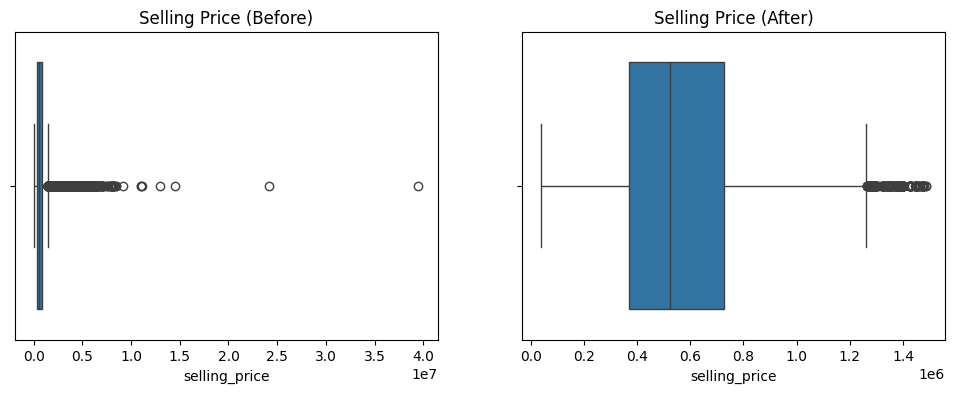

In [65]:
#outliers graph
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.boxplot(x=df['selling_price'])
plt.title("Selling Price (Before)")

plt.subplot(1, 2, 2)
sns.boxplot(x=df_clean['selling_price'])
plt.title("Selling Price (After)")

plt.show()

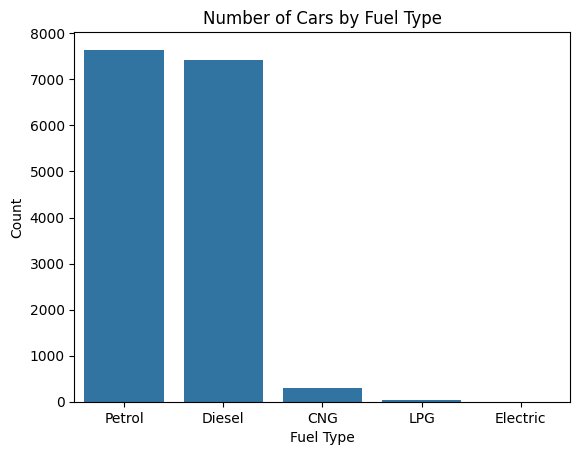

In [67]:
#univariate analysis
sns.countplot(x=df['fuel_type'])
plt.title("Number of Cars by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Count")
plt.show()

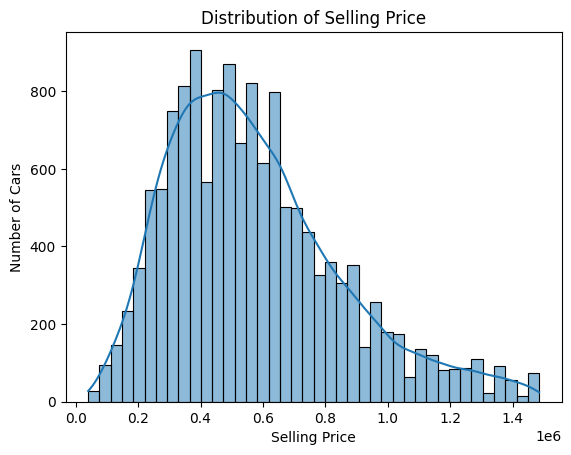

In [68]:
sns.histplot(df_clean['selling_price'], bins=40, kde=True)
plt.title("Distribution of Selling Price")
plt.xlabel("Selling Price")
plt.ylabel("Number of Cars")
plt.show()

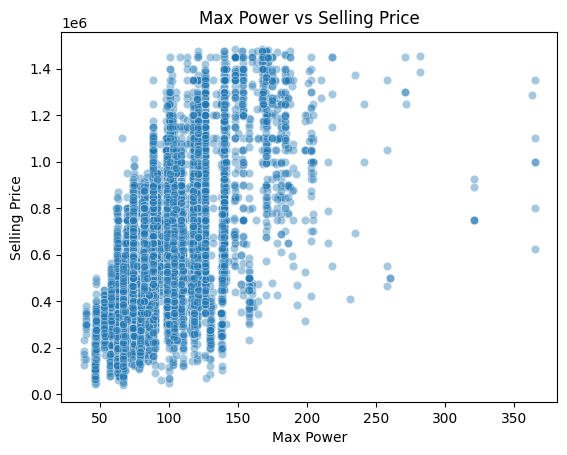

In [69]:
#bivariate analysis
sns.scatterplot(x=df_clean['max_power'], y=df_clean['selling_price'], alpha=0.4)
plt.title("Max Power vs Selling Price")
plt.xlabel("Max Power")
plt.ylabel("Selling Price")
plt.show()

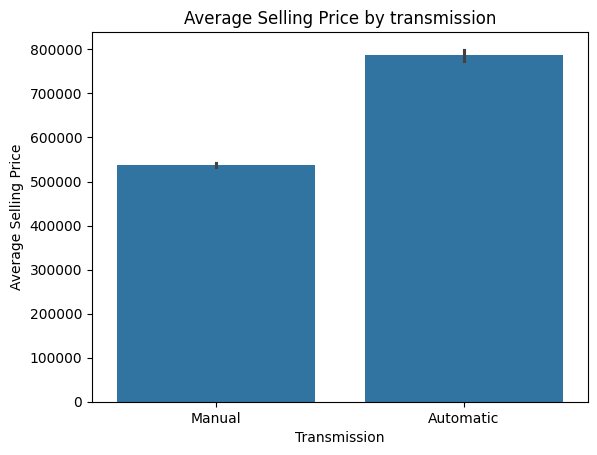

In [70]:
sns.barplot(x=df_clean['transmission_type'], y=df_clean['selling_price'])
plt.title("Average Selling Price by transmission")
plt.xlabel("Transmission")
plt.ylabel("Average Selling Price")
plt.show()

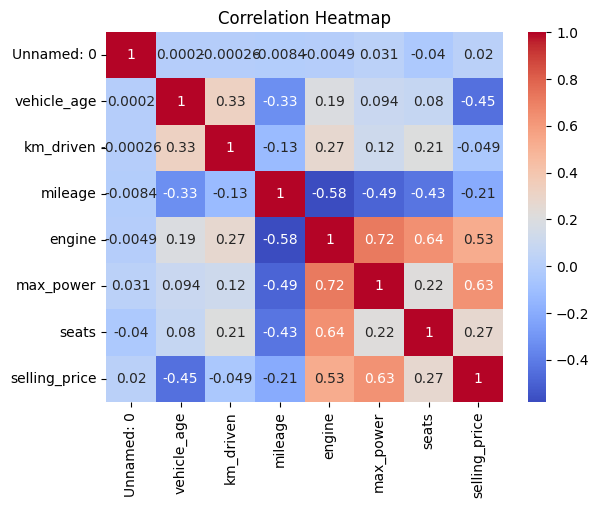

In [71]:
# multivariate analysis
sns.heatmap(df_clean.select_dtypes(include='number').corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()